# 01. Data exploration

**Project:** pmt-Burundi, poverty classification with Proxy Means Testing (DSA 8401 capstone)

**Purpose:** understand the data well enough to justify every cleaning and modelling decision. No model is trained here.

**Input:** `data/raw/hh.csv` (household data, restricted, not included in the repository) and the household codebook (Excel).

**Output:** a decision log (`docs/decision_log.md`) and the final predictor list (`docs/final_predictors.txt`), which feed `src/preprocess.py`. The notebook does not write any household data.

## This step includes the following steps: 

1. **Load and first look**: shape, column types and a first view of the rows.
2. **Codebook lookup**: a dictionary that translates variable codes into plain labels.
3. **Completed interviews**: keep only households with a completed interview.
4. **Target construction**: inspect `m11cons`, build the binary poor / not poor label, check class balance.
5. **Leakage test**: show why the existing wealth index is rejected as a target.
6. **Predictor audit**: types, missing values and structural missingness per predictor group.
7. **Exclusions**: variables removed from the predictors, with the reason for each.
8. **Sanity checks**: poverty rate by urban/rural, province, education and key assets.
9. **Decision log**: the cleaning and encoding rules carried into the pipeline.

# 1. LOAD & FIRST LOOK

In [58]:

# Import the libraries used throughout the notebook.
import pandas as pd
import numpy as np
import os

# Load the household data from the raw folder.
data_path = "../data/raw/hh.csv"
df = pd.read_csv(data_path)

# Report the size: households (rows) and variables (columns).
print("Shape:", df.shape)

# Count the variables by data type, to see how many are numeric versus text.
print("\nColumn types:")
print(df.dtypes.value_counts())

# Report the overall share of missing values across the whole table.
print(f"\nOverall missing: {df.isna().mean().mean():.1%}")

# List the names of the text columns (names only, no values).
print("\nText columns:", df.select_dtypes(exclude="number").columns.tolist())

# Preview the first 5 households without identifiers, names or GPS,
# so that no personal data is saved in the notebook output.
pii_cols = ["interview_key", "interview_id", "hh2nom"] + [c for c in df.columns if c.lower().startswith("gps")]
df.drop(columns=pii_cols).iloc[:5, :8]

Shape: (7824, 221)

Column types:
float64    211
str         10
Name: count, dtype: int64

Overall missing: 23.7%

Text columns: ['interview_key', 'interview_id', 'hh2nom', 'hh5', 'gpsd_Timestamp', 'hc1a_other', 'hc1c_other', 'hh9other', 'heuredebut', 'responsible']


,hh1,hh2,hh5,hh6,prov5,hh1a,hha1_bis,hh7
0,1.0,1.0,2023-04-20T14:27:32,1.0,2.0,1.0,1.0,4.0
1,1.0,2.0,2023-04-20T10:57:13,1.0,2.0,1.0,1.0,4.0
2,1.0,3.0,2023-04-20T14:08:32,1.0,2.0,1.0,1.0,4.0
3,1.0,4.0,2023-04-20T11:54:45,1.0,2.0,1.0,1.0,4.0
4,1.0,5.0,2023-04-20T14:07:31,1.0,2.0,1.0,1.0,4.0


# 2. CODEBOOK LOOKUP

In [59]:
# PART I: INSPECT THE LAYOUT
# Path to the codebook in the raw folder, and a check that the file is really there.
codebook_path = "../data/raw/household codebook file - Translation.xlsx"
print("Codebook found:", os.path.exists(codebook_path))

# Read every sheet without assuming a header row, so the raw layout stays visible.
sheets = pd.read_excel(codebook_path, sheet_name=None, header=None)

# Show the name, size and first rows of each sheet.
for name, sheet in sheets.items():
    print(f"\nSheet '{name}': {sheet.shape}")
    display(sheet.head(8))

Codebook found: True

Sheet 'Sheet1': (1571, 5)


,0,1,2,3,4
0,Variable Information,NaN,NaN,NaN,NaN
1,Variable,Position,Label,Translation,NaN
2,interview_key,1,Interview key (identifier in XX-XX-XX-XX format),Interview key,NaN
3,interview_id,2,Unique 32-character long identifier of the int...,Interview Id,NaN
4,hh1,3,N° de la grappe,Cluster Number,NaN
5,hh2,4,N° du ménage,Household Id,NaN
6,hh2nom,5,Nom du chef de ménage,Household Head's name,NaN
7,hh5,6,Début de l'interwiew,Interview start,NaN


In [60]:
# PART II: Build the code-to-label dictionary

# Name the columns, then drop the title row and the header row.
cb = sheets["Sheet1"].copy()
cb.columns = ["variable", "position", "label", "translation", "extra"]
cb = cb.iloc[2:].reset_index(drop=True)

# Rows with a numeric position are variables; the first row without one marks a new section.
cb["pos_num"] = pd.to_numeric(cb["position"], errors="coerce")
first_break = cb["pos_num"].isna().idxmax()
print(f"Variable block: rows 0 to {first_break - 1} ({first_break} variables)")

# Show the first rows after the break, to see what the other sections contain.
display(cb.iloc[first_break:first_break + 8, :4])

# Keep only the variable block and build the dictionary, using the English translation when it exists.
var_block = cb.iloc[:first_break]
labels = dict(zip(var_block["variable"], var_block["translation"].fillna(var_block["label"])))

# Safeguard against a repeat of the hh9 mix-up: the codebook position must match the column order in df.
mismatch = [v for v, p in zip(var_block["variable"], var_block["pos_num"])
            if v in df.columns and df.columns.get_loc(v) + 1 != p]
print("Variables in codebook but not in data:", [v for v in labels if v not in df.columns])
print("Variables in data but not in codebook:", [c for c in df.columns if c not in labels])
print("Position mismatches:", mismatch)

# Look up the variables we need to understand.
for v in ["hh1", "hh9", "hh9other", "hh11", "responsible", "m11cons", "wlthscor", "wlthind5", "interview_status"]:
    print(f"{v:18} -> {labels.get(v, 'NOT FOUND')}")

Variable block: rows 0 to 220 (221 variables)


,variable,position,label,translation
221,Variables in the working file,NaN,NaN,NaN
222,NaN,NaN,NaN,NaN
223,Variable Values,NaN,NaN,NaN
224,Value,NaN,Label,Translation
225,hh1,"-999999999,000a",missing,-
226,hh6,1,Rural,Rural
227,NaN,2,Urbain,Urban
228,gpsd_Latitude,"-999999999,00000000a",missing,-


Variables in codebook but not in data: [1]
Variables in data but not in codebook: ['hh17b']
Position mismatches: []
hh1                -> Cluster Number
hh9                -> Household Interview Result
hh9other           -> Other(Precise)
hh11               -> Household size
responsible        -> Last responsible person
m11cons            -> Number of items consumed
wlthscor           -> Wealth index factor score
wlthind5           -> Wellbeing Quantiles
interview_status   -> Status of the interview


In [61]:
# PART III: Resolve the name mismatch and parse the value labels

# Show the codebook row whose name is a number, next to the position of hh17b in the data.
odd = var_block[pd.to_numeric(var_block["variable"], errors="coerce").notna()]
display(odd[["variable", "position", "translation"]])
print("hh17b position in data:", df.columns.get_loc("hh17b") + 1)

# Locate the value-label section; the variable name appears only on the first row of each variable.
start = cb.index[cb["variable"] == "Variable Values"][0]
vb = cb.iloc[start + 2:].copy()
vb["variable"] = vb["variable"].ffill()
vb = vb.dropna(subset=["position"])

# Convert codes such as "-999999999,000a" to numbers by fixing the decimal comma and dropping the letter.
vb["code"] = pd.to_numeric(vb["position"].astype(str).str.replace(",", ".").str.rstrip("a"), errors="coerce")

# Build value_labels[variable][code] = English label, falling back to the original label.
vb["text"] = vb["translation"].fillna(vb["label"])
value_labels = {v: dict(zip(g["code"], g["text"])) for v, g in vb.groupby("variable")}
print("Variables with value labels:", len(value_labels))

# Check three examples, and whether hh17b has labels under its own name.
for v in ["hh6", "interview_status", "hh9"]:
    print(v, value_labels.get(v))
print("hh17b has value labels:", "hh17b" in value_labels)

# Count cells holding the -999999999 missing-value code in the data.
num = df.select_dtypes("number")
print("Cells holding the -999999999 code:", int((num == -999999999).sum().sum()))

,variable,position,translation
34,1,35,"If yes, how much income did this activity gene..."


hh17b position in data: 35
Variables with value labels: 201
hh6 {1.0: 'Rural', 2.0: 'Urban'}
interview_status {-999999999.0: '-', -1.0: 'Deleted', 0.0: 'Restored', 20.0: 'Created', 40.0: 'SupervisorAssigned', 60.0: 'InterviewerAssigned', 65.0: 'RejectedBySupervisor', 80.0: 'ReadyForInterview', 85.0: 'SentToCapi', 95.0: 'Restarted', 100.0: 'Completed', 120.0: 'ApprovedBySupervisor', 125.0: 'RejectedByHeadquarters', 130.0: 'ApprovedByHeadquarters'}
hh9 {-999999999.0: '-', 1.0: 'Filled', 2.0: 'Not home', 3.0: 'Refused', 4.0: 'Partially filled', 5.0: 'Other(Precise)'}
hh17b has value labels: True
Cells holding the -999999999 code: 0


In [62]:
# Part IV: Fix the mistyped codebook name and add a lookup helper

# The only name in the codebook that is not a column in df is the mistyped one at position 35.
bad = [k for k in labels if k not in df.columns]
for k in bad:
    labels["hh17b"] = labels.pop(k)

# Every column in df should now have an English label.
print("Columns without a label:", [c for c in df.columns if c not in labels])

# Helper: print a variable's English name and the meaning of each of its codes.
def show(var):
    print(f"{var} -> {labels.get(var, 'NOT FOUND')}")
    for code, text in value_labels.get(var, {}).items():
        print(f"   {code:g}: {text}")

show("hh17b")
show("hh9")

Columns without a label: []
hh17b -> If yes, how much income did this activity generate in 2022 (in FBu)?
   -1e+09: -
hh9 -> Household Interview Result
   -1e+09: -
   1: Filled
   2: Not home
   3: Refused
   4: Partially filled
   5: Other(Precise)


In [63]:
# Part V: Compare df with a readable view built from the dictionaries

# Proof that df is unchanged since Stage 1.
print("df shape:", df.shape)

# Pick a few non-identifying variables to compare (only those that exist in the data).
wanted = ["hh1", "hh6", "hh7", "prov5", "hh11", "m11cons"]
cols = [c for c in wanted if c in df.columns]

# Before: the first 5 households exactly as stored in df, as numeric codes.
before = df[cols].head(5)
print("\nBEFORE (df as stored):")
display(before)

# After: a copy where codes are replaced by their meaning and columns show code | English name.
after = before.copy()
for c in cols:
    if c in value_labels:
        after[c] = before[c].map(value_labels[c]).fillna(before[c])
after.columns = [f"{c} | {labels[c]}" for c in cols]
print("\nAFTER (readable copy, df is not modified):")
display(after)

# How many variables the codebook can decode, out of all columns.
print(f"\nVariables with decodable values: {len(value_labels)} of {df.shape[1]}")

df shape: (7824, 221)

BEFORE (df as stored):


,hh1,hh6,hh7,prov5,hh11,m11cons
0,1.0,1.0,4.0,2.0,6.0,15.0
1,1.0,1.0,4.0,2.0,8.0,31.0
2,1.0,1.0,4.0,2.0,8.0,12.0
3,1.0,1.0,4.0,2.0,3.0,14.0
4,1.0,1.0,4.0,2.0,4.0,22.0



AFTER (readable copy, df is not modified):


C:\Users\dsimiyu\AppData\Local\Temp\ipykernel_35768\1720790675.py:19: Pandas4Warning: 'ndarray' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  after[c] = before[c].map(value_labels[c]).fillna(before[c])


,hh1 | Cluster Number,hh6 | Residence Area,hh7 | Region,prov5 | New administrative subdivision,hh11 | Household size,m11cons | Number of items consumed
0,1.0,Rural,West,BUJUMBURA,6.0,15.0
1,1.0,Rural,West,BUJUMBURA,8.0,31.0
2,1.0,Rural,West,BUJUMBURA,8.0,12.0
3,1.0,Rural,West,BUJUMBURA,3.0,14.0
4,1.0,Rural,West,BUJUMBURA,4.0,22.0



Variables with decodable values: 201 of 221


# 3. COMPLETED INTERVIEWS

In [64]:
# PART I : Who is in the data? Compare the review status, the visit result and target availability

# Safety check carried over from Step 2 : Part IV
print("Columns without a label:", [c for c in df.columns if c not in labels])

# Readable versions of the two status variables (display only, df is unchanged).
status = df["interview_status"].map(value_labels["interview_status"])
visit = df["hh9"].map(value_labels["hh9"])

# Cross-tab: review status (rows) against visit result (columns).
display(pd.crosstab(status, visit, dropna=False, margins=True))

# Is the target available? Households with a usable m11cons, and missing m11cons by visit result.
print("\nm11cons available:", df["m11cons"].notna().sum(), "of", len(df))
print("\nm11cons missing, by visit result:")
print(df["m11cons"].isna().groupby(visit, dropna=False).agg(["sum", "count"]))

Columns without a label: []


hh9,Filled,Not home,Partially filled,All
interview_status,,,,
ApprovedByHeadquarters,360,0,3,363
ApprovedBySupervisor,7047,0,13,7060
Completed,0,0,1,1
RejectedBySupervisor,0,0,1,1
NaN,0,399,0,399
All,7407,399,18,7824



m11cons available: 7425 of 7824

m11cons missing, by visit result:
                  sum  count
hh9                         
Filled              0   7407
Not home          399    399
Partially filled    0     18


In [65]:
# Step 3, Part 2: Compare the households we would drop with the ones we keep

# Readable visit result, used as the grouping variable.
visit = df["hh9"].map(value_labels["hh9"])

# Composition by urban/rural and by province, as % within each visit result.
for var in ["hh6", "prov5"]:
    readable = df[var].map(value_labels[var]).fillna("(missing)")
    print(f"\n{var} | {labels[var]} (% within each visit result)")
    display(pd.crosstab(readable, visit, normalize="columns").mul(100).round(1))

# Target and share of empty cells per row, by visit result: are the 18 partial households usable?
print("\nm11cons by visit result:")
print(df.groupby(visit)["m11cons"].describe().round(1))
print("\nShare of empty cells per household, average by visit result:")
print(df.isna().mean(axis=1).groupby(visit).mean().round(3))


hh6 | Residence Area (% within each visit result)


hh9,Filled,Not home,Partially filled
hh6,,,
Rural,90.5,67.2,88.9
Urban,9.5,32.8,11.1



prov5 | New administrative subdivision (% within each visit result)


hh9,Filled,Not home,Partially filled
prov5,,,
BUHUMUZA,19.3,8.5,5.6
BUJUMBURA,23.6,48.1,55.6
BURUNGA,19.0,27.3,27.8
Butanyerera,17.4,8.3,0.0
Gitega,20.6,7.8,11.1



m11cons by visit result:
                   count  mean  std  min   25%   50%   75%   max
hh9                                                             
Filled            7407.0  13.7  5.2  1.0  10.0  13.0  17.0  43.0
Not home             0.0   NaN  NaN  NaN   NaN   NaN   NaN   NaN
Partially filled    18.0   6.9  6.4  0.0   1.0   6.5  12.2  17.0

Share of empty cells per household, average by visit result:
hh9
Filled              0.198
Not home            0.964
Partially filled    0.365
dtype: float64


In [66]:
# Step 3, Part 3: Apply the filter and start the decision log

# Keep only households with a filled interview (hh9 = 1); df itself stays unchanged.
df_kept = df[df["hh9"] == 1].copy()

# Reconcile the counts: kept, and dropped by reason, so no household is lost unexplained.
dropped = df.loc[df["hh9"] != 1, "hh9"].map(value_labels["hh9"]).value_counts()
print("Total:", len(df), "| Kept:", len(df_kept), "| Dropped:", int(dropped.sum()))
print(dropped.to_dict())

# The target must be complete in the kept data.
print("m11cons missing in kept data:", df_kept["m11cons"].isna().sum())

# Start the decision log, which Step 9 will turn into the final list.
decision_log = [
    "Population: keep only households with hh9 = Filled (7,407 of 7,824, 94.7%). interview_status is a review workflow, not completion, so it is not used.",
    "Dropped 399 'Not home' households: no data, target missing. Non-response is concentrated in BUJUMBURA (48% vs 24%), so the model under-represents these households (limitation).",
    "Dropped 18 'Partially filled' households: m11cons is truncated (mean 6.9 vs 13.7), so the poverty label would be unreliable.",
    "Train/test split must be grouped by cluster (hh1), because households in a cluster resemble each other.",
    "Text columns (identifiers, names, timestamps, free text) are never predictors.",
]
print(f"\nDecision log: {len(decision_log)} entries")

Total: 7824 | Kept: 7407 | Dropped: 417
{'Not home': 399, 'Partially filled': 18}
m11cons missing in kept data: 0

Decision log: 5 entries


## Step 4. TARGET CONSTRUCTION
Builds the binary poor / not poor label from `m11cons` (bottom two quintiles) and checks the class balance.

In [67]:
# Step 4, Part 1: Build the poor / not poor label from m11cons

# Distribution of the target: count, cumulative share and a quick text bar for each value.
dist = df_kept["m11cons"].value_counts().sort_index()
dist_table = pd.DataFrame({"households": dist, "cum_%": (dist.cumsum() / len(df_kept) * 100).round(1)})
dist_table["bar"] = ["#" * int(n / dist.max() * 30) for n in dist]
display(dist_table)

# Cut-off at the 40th percentile: households at or below it are labelled poor (1).
cutoff = df_kept["m11cons"].quantile(0.40)
df_kept["poor"] = (df_kept["m11cons"] <= cutoff).astype(int)
print(f"Cut-off (40th percentile): {cutoff}")

# Class balance: no imbalance handling is needed if neither class is very small.
print(df_kept["poor"].value_counts().rename({1: "poor", 0: "not poor"}))
print(f"Share poor: {df_kept['poor'].mean():.1%}")

# Record the decision.
decision_log.append(f"Target: poor = 1 if m11cons <= {cutoff:g} (40th percentile of the kept data). Label is relative to this data, not an official poverty line. Share poor: {df_kept['poor'].mean():.1%}.")

,households,cum_%,bar
m11cons,,,
1.0,7,0.1,
2.0,41,0.6,#
3.0,33,1.1,#
4.0,63,1.9,###
5.0,132,3.7,######
6.0,171,6.0,########
7.0,303,10.1,##############
8.0,351,14.9,#################
9.0,474,21.3,#######################


Cut-off (40th percentile): 12.0
poor
not poor    4155
poor        3252
Name: count, dtype: int64
Share poor: 43.9%


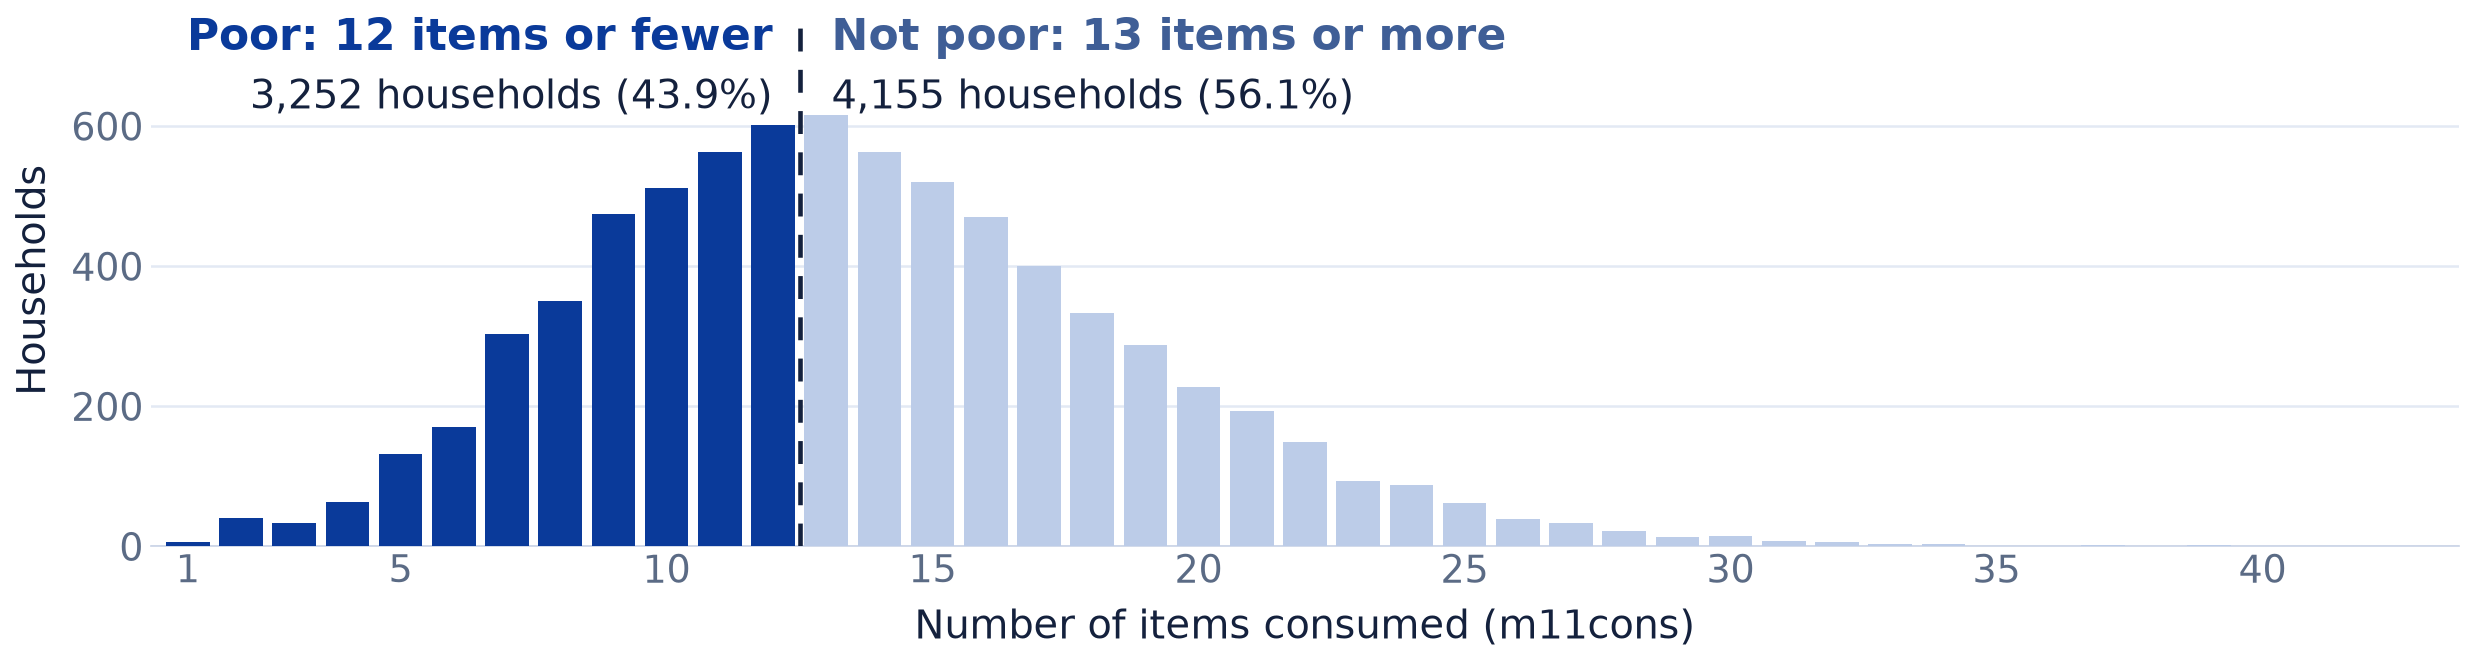

In [68]:
# Part X: Histogram of m11cons with the poverty line (same chart as on the slide)
import matplotlib.pyplot as plt

# Strathmore-style colors used on the slides
NAVY, LIGHT = "#0A3A9A", "#BCCCE8"
INK, MUTED, GRID = "#14213D", "#5B6B85", "#E3E9F4"

# CHANGE THIS LINE: the column of m11cons for the 7,407 completed households.
# Use the same dataframe name you used when you built the poor label.
m11 = df_kept["m11cons"]

# Count households per value of m11cons (1 to 43), filling gaps with 0
counts = m11.value_counts().reindex(range(1, 44), fill_value=0)
total = int(counts.sum())
poor = int(counts.loc[:12].sum())

# Safety checks: these must match the numbers on the slide
assert total == 7407 and poor == 3252

fig, ax = plt.subplots(figsize=(16.64, 4.55), dpi=150)

# Dark bars = poor (12 or fewer), light bars = not poor
colors = [NAVY if x <= 12 else LIGHT for x in counts.index]
ax.bar(counts.index, counts.values, width=0.82, color=colors, zorder=3)

# Dashed line between 12 and 13
ax.axvline(12.5, color=INK, lw=2.2, ls=(0, (5, 4)), zorder=4)

ax.set_xlim(0.3, 43.7)
ax.set_ylim(0, 760)
ax.set_xticks([1, 5, 10, 15, 20, 25, 30, 35, 40])
ax.set_yticks([0, 200, 400, 600])
ax.tick_params(axis="both", labelsize=18, colors=MUTED, length=0)
ax.grid(axis="y", color=GRID, lw=1.2, zorder=0)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#C9D3E6")
ax.set_xlabel("Number of items consumed (m11cons)", fontsize=19, color=INK, labelpad=8)
ax.set_ylabel("Households", fontsize=19, color=INK, labelpad=8)

# Labels above each side of the line
ax.text(12.0, 725, "Poor: 12 items or fewer", ha="right", va="center",
        fontsize=21, fontweight="bold", color=NAVY)
ax.text(12.0, 640, f"{poor:,} households ({100*poor/total:.1f}%)", ha="right", va="center",
        fontsize=19, color=INK)
ax.text(13.1, 725, "Not poor: 13 items or more", ha="left", va="center",
        fontsize=21, fontweight="bold", color="#3F5E96")
ax.text(13.1, 640, f"{total-poor:,} households ({100*(total-poor)/total:.1f}%)", ha="left", va="center",
        fontsize=19, color=INK)

fig.subplots_adjust(left=0.065, right=0.99, top=0.98, bottom=0.2)

# Save a copy for the repo, then show it
fig.savefig("../docs/figures/m11cons_histogram.png", facecolor="white")
plt.show()

## Step 5. LEAKAGE TESTS
Shows why the existing wealth index is rejected as the target: it can be predicted almost directly from the housing and asset variables, whereas the item count cannot.

In [69]:
# Step 5, Part 1: Predict each candidate target from housing, water and asset variables

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score
import re

# Proxy variables: numeric columns for housing (hc), water and sanitation (ws) and nets (tn), including the 24 assets.
proxy_cols = [c for c in df_kept.select_dtypes("number").columns if re.match(r"^(hc|ws|tn)\d", c)]
print(len(proxy_cols), "proxy variables")

# Skipped questions are empty by design, so fill them with -1 for this simple test.
X = df_kept[proxy_cols].fillna(-1)

# Split by cluster (hh1), so households from one cluster stay together, as recorded in the decision log.
train_idx, test_idx = next(GroupShuffleSplit(test_size=0.25, random_state=42).split(X, groups=df_kept["hh1"]))

# Same method for both targets: fit on the training clusters, score (R2) on the unseen test clusters.
results = {}
for target in ["wlthscor", "m11cons"]:
    ok = df_kept[target].notna()
    tr, te = train_idx[ok.iloc[train_idx].values], test_idx[ok.iloc[test_idx].values]
    model = LinearRegression().fit(X.iloc[tr], df_kept[target].iloc[tr])
    results[target] = r2_score(df_kept[target].iloc[te], model.predict(X.iloc[te]))
    print(f"{target:10} {labels[target]:35} test R2 = {results[target]:.3f}")

# Record the decision.
decision_log.append(f"Wealth index (wlthscor, wlthind5) rejected as target: predictable from the housing and asset variables (test R2 {results['wlthscor']:.2f}, cluster-grouped split), so it is circular. m11cons is far less predictable (test R2 {results['m11cons']:.2f}).")

117 proxy variables
wlthscor   Wealth index factor score           test R2 = -39.772
m11cons    Number of items consumed            test R2 = -82.841


In [70]:
# Step 5, Part 2: Find what breaks the test R2

# Training score for the same model: if it is sensible, the problem is unseen values in the test clusters.
m = LinearRegression().fit(X.iloc[train_idx], df_kept["m11cons"].iloc[train_idx])
print("m11cons train R2:", round(r2_score(df_kept["m11cons"].iloc[train_idx], m.predict(X.iloc[train_idx])), 3))

# Largest prediction error in the test clusters.
pred = m.predict(X.iloc[test_idx])
print("Prediction range on test:", pred.min().round(1), "to", pred.max().round(1))

# Columns with unusual codes (above 90) and how many households have them.
big = (X > 90).sum()
display(big[big > 0].sort_values(ascending=False).head(10).rename("households").to_frame().assign(name=lambda d: d.index.map(labels)))

m11cons train R2: 0.235
Prediction range on test: 3.9 to 1778.2


,households,name
hc6a,2847,Main source of lighting
hc12,1796,How many ares of agricultural land do househol...
tn5,524,How long have you had the most recent mosquito...
ws3,507,"How long does it take to go there, collect wat..."
hc9_23,373,Hoe
hc9_13,290,Chairs
hc9_14,262,Dining table
hc9_9,239,Mobile phone
hc9_24,213,Axe
hc5,181,Main material of the walls


In [71]:
# Step 5, Part 3: Redo the leakage test with a tree-based model (robust to mixed codes and extreme values)

from sklearn.ensemble import HistGradientBoostingRegressor

# Remove the entry written by Step 5, Part 1, which came from the broken linear test.
decision_log[:] = [d for d in decision_log if not d.startswith("Wealth index")]

# Same proxy variables and same cluster-grouped split as before; empty cells stay empty.
X = df_kept[proxy_cols]

# Same method for both targets: fit on training clusters, score (R2) on unseen test clusters.
results = {}
for target in ["wlthscor", "m11cons"]:
    ok = df_kept[target].notna()
    tr, te = train_idx[ok.iloc[train_idx].values], test_idx[ok.iloc[test_idx].values]
    model = HistGradientBoostingRegressor(max_iter=200, random_state=42).fit(X.iloc[tr], df_kept[target].iloc[tr])
    results[target] = r2_score(df_kept[target].iloc[te], model.predict(X.iloc[te]))
    print(f"{target:10} {labels[target]:35} test R2 = {results[target]:.3f}")

# Record the decision.
decision_log.append(f"Wealth index (wlthscor, wlthind5) rejected as target: predictable from the housing and asset variables (test R2 {results['wlthscor']:.2f}, tree model, cluster-grouped split), so it is circular. m11cons is far less predictable (test R2 {results['m11cons']:.2f}). A linear model failed on these columns because category codes and real quantities are mixed; to be fixed in Step 6.")

wlthscor   Wealth index factor score           test R2 = 0.995
m11cons    Number of items consumed            test R2 = 0.380


## Step 6. PREDICTOR AUDITS
Lists the candidate predictors by group and checks the type, the missing values and the unusual codes of each one.

In [72]:
# Step 6, Part 1: Group the candidate predictors and find the head-of-household variables

# Prefix-based groups: housing and assets (hc), water and sanitation (ws), nets (tn).
groups = {
    "housing and assets (hc)": [c for c in df_kept.columns if re.match(r"^hc\d", c)],
    "water and sanitation (ws)": [c for c in df_kept.columns if re.match(r"^ws\d", c)],
    "mosquito nets (tn)": [c for c in df_kept.columns if re.match(r"^tn\d", c)],
    "household size and location": [c for c in ["hh11", "hh6", "hh7", "prov5"] if c in df_kept.columns],
}
for g, cols in groups.items():
    print(f"{g}: {len(cols)} variables")

# Find the head-of-household variables by searching the English labels (names excluded).
others = [c for c in df_kept.columns if not re.match(r"^(hc|ws|tn)\d", c) and c != "hh2nom"]
for c in others:
    if re.search(r"head|marital|education|sex|age\b", str(labels.get(c, "")), re.I):
        print(f"{c:12} | {labels[c]}")

housing and assets (hc): 67 variables
water and sanitation (ws): 18 variables
mosquito nets (tn): 34 variables
household size and location: 4 variables
hh19b_3      | If yes, was it in: Education?
l17ycm       | Head of household under 17 years
cmexiste     | Existence of a head of household
ctrled       | Inconsistencies between education level and completed grade (ED3A and ED3B)
ctrled1      | Inconsistencies between education level and grade (ED6 and ED6B)
ctrled2      | Inconsistencies between education level and grade (ED8A and ED8B)
m3d          | Bride price and marriage expenses
hhmstatus    | Marital status of head of household
hhage        | Age of head of household
helevel      | Education level of head of household
hhsex        | Sex of head of household


In [73]:
# Step 6, Part 2: Classify each predictor as category, numeric or mixed

# Candidate predictors: the three prefix groups plus household size, location and head variables (numeric only).
head_cols = ["hhage", "hhsex", "hhmstatus", "helevel"]
numeric_cols = set(df_kept.select_dtypes("number").columns)
predictors = list(dict.fromkeys(c for g in groups.values() for c in g + head_cols if c in numeric_cols))
print(len(predictors), "candidate predictors")

# For each variable, compare the values in the data with the real codes in the codebook (the -999999999 legend is ignored).
rows = []
for c in predictors:
    s = df_kept[c].dropna()
    real = {k: v for k, v in value_labels.get(c, {}).items() if k > -999999999}
    unlabeled = (~s.isin(list(real))).mean() if len(s) else 0
    kind = "numeric" if not real else ("category" if unlabeled < 0.05 else "mixed")
    rows.append({"var": c, "label": str(labels[c])[:45], "type": kind, "n_unique": s.nunique(),
                 "min": s.min(), "max": s.max(), "missing_%": round(df_kept[c].isna().mean() * 100, 1)})
audit = pd.DataFrame(rows).set_index("var")

# Summary by type, then the variables that need a decision (numeric and mixed).
print(audit["type"].value_counts().to_dict())
display(audit[audit["type"] != "category"].sort_values("type"))

125 candidate predictors
{'numeric': 56, 'category': 51, 'mixed': 18}


,label,type,n_unique,min,max,missing_%
var,,,,,,
hc14_5,Chickens,mixed,26,0.0,98.0,40.1
ws3,"How long does it take to go there, collect wa",mixed,64,0.0,35000.0,0.0
hc14_8,Guinea pigs,mixed,36,0.0,15000.0,40.1
hc14_7,Pigs,mixed,15,0.0,98.0,40.1
hc14_6,Rabbits,mixed,22,0.0,98.0,40.1
...,...,...,...,...,...,...
ws6_6,Do you do anything to make the water safer be,numeric,2,0.0,1.0,98.7
ws6_7,Do you do anything to make the water safer be,numeric,2,0.0,1.0,98.7
ws9,"In total, how many households use this toilet",numeric,19,0.0,25.0,1.6


In [74]:
# Step 6, Part 3: Inspect the mixed variables and the numeric variables with large values

# Show the full list of mixed variables (no row limit).
with pd.option_context("display.max_rows", None, "display.width", 200):
    display(audit[audit["type"] == "mixed"][["label", "n_unique", "min", "max", "missing_%"]])

# For each mixed variable, show which labelled codes actually occur in the data: {code: (label, households)}.
for c in audit.index[audit["type"] == "mixed"]:
    real = {k: v for k, v in value_labels[c].items() if k > -999999999}
    found = {int(k): (str(v)[:18], int((df_kept[c] == k).sum())) for k, v in real.items() if (df_kept[c] == k).any()}
    print(f"{c:9} {found}")

# Numeric variables with values above 99: possible special codes or outliers.
with pd.option_context("display.max_rows", None, "display.width", 200):
    display(audit[(audit["type"] == "numeric") & (audit["max"] > 99)][["label", "min", "max", "missing_%"]])

,label,n_unique,min,max,missing_%
var,,,,,
hc9_7,Radio,12,0.00,100000.0,0.0
hc9_9,Mobile phone,19,0.00,530000.0,0.0
hc9_13,Chairs,26,0.00,400000.0,0.0
hc9_14,Dining table,17,0.00,100000.0,0.0
hc9_16,Bicycle,8,0.00,98.0,0.0
hc9_23,Hoe,20,0.00,33000.0,0.0
hc9_24,Axe,15,0.00,44000.0,0.0
hc12,How many ares of agricultural land do househo,198,0.24,35000.0,22.6
hc14_1,Large livestock (other than cattle),17,0.00,98.0,40.1


hc9_7     {0: ('Aucun', 5733), 97: ('97 and above', 135), 98: ('Not known', 3)}
hc9_9     {0: ('Aucun', 4128), 97: ('97 and above', 232)}
hc9_13    {0: ('Aucun', 4310), 97: ('97 and above', 277), 98: ('Not known', 5)}
hc9_14    {0: ('Aucun', 4370), 97: ('97 and above', 244), 98: ('Not known', 3)}
hc9_16    {0: ('Aucun', 6593), 97: ('97 and above', 60), 98: ('Not known', 2)}
hc9_23    {0: ('Aucun', 976), 97: ('97 and above', 366), 98: ('Not known', 2)}
hc9_24    {0: ('Aucun', 5248), 97: ('97 and above', 208), 98: ('Not known', 2)}
hc12      {997: ('997 ares and above', 434), 998: ('Not known', 574)}
hc14_1    {0: ('Aucun', 4089), 97: ('97 and above', 43), 98: ('Not known', 15)}
hc14_2    {0: ('Aucun', 3234), 97: ('97 and above', 65), 98: ('Not known', 5)}
hc14_3    {0: ('Aucun', 1680), 97: ('97 and above', 120), 98: ('Not known', 3)}
hc14_4    {0: ('Aucun', 4098), 97: ('97 and above', 22), 98: ('Not known', 6)}
hc14_5    {0: ('Aucun', 3006), 97: ('97 and above', 81), 98: ('Not known', 3

,label,min,max,missing_%
var,,,,
hhage,Age of head of household,17.0,102.0,0.0


In [75]:
# Step 6, Part 4: Count implausible values in the mixed variables, and reprint what Part 3 cut off

# The highest labelled code ("Not known") is the ceiling of valid values; anything above it is implausible.
rows = []
for c in audit.index[audit["type"] == "mixed"]:
    ceiling = max(k for k in value_labels[c] if k > -999999999)
    rows.append({"var": c, "ceiling": ceiling, "households_over": int((df_kept[c] > ceiling).sum()), "largest": df_kept[c].max()})
over = pd.DataFrame(rows).set_index("var")
display(over[over["households_over"] > 0])

# Labelled codes found in the data for the three variables whose output was cut off.
for c in ["hc14_8", "ws3", "tn5"]:
    real = {k: v for k, v in value_labels[c].items() if k > -999999999}
    found = {int(k): (str(v)[:18], int((df_kept[c] == k).sum())) for k, v in real.items() if (df_kept[c] == k).any()}
    print(f"{c:9} {found}")


,ceiling,households_over,largest
var,,,
hc9_7,98.0,4,100000.0
hc9_9,98.0,7,530000.0
hc9_13,98.0,8,400000.0
hc9_14,98.0,15,100000.0
hc9_23,98.0,5,33000.0
hc9_24,98.0,3,44000.0
hc12,998.0,45,35000.0
hc14_8,98.0,2,15000.0
ws3,998.0,3,35000.0


hc14_8    {0: ('Aucun', 3462), 97: ('97 and above', 44), 98: ('Not known', 8)}
ws3       {995: ('Water on premises', 230), 998: ('Not known', 130)}
tn5       {95: ('More than 24 month', 202), 98: ('Not known / Not su', 321)}


In [76]:
# Step 6, Part 5: Apply the cleaning rules to a copy, then recheck the linear model that failed in Step 5

# Rule 1: "Not known" codes and anything above them become empty.
clean = df_kept.copy()
mixed = list(audit.index[audit["type"] == "mixed"])
before = clean[mixed].isna().sum().sum()
for c in mixed:
    ceiling = max(k for k in value_labels[c] if k > -999999999)
    clean.loc[clean[c] >= ceiling, c] = np.nan

# Rules 3 and 4: the two category codes hidden inside numeric columns.
clean.loc[clean["ws3"] == 995, "ws3"] = 0
clean.loc[clean["tn5"] == 95, "tn5"] = 25
print("Cells turned empty:", int(clean[mixed].isna().sum().sum() - before))

# Same linear test as Step 5, Part 1 (same split, empty cells filled with -1).
X = clean[proxy_cols].fillna(-1)
lin = LinearRegression().fit(X.iloc[train_idx], clean["m11cons"].iloc[train_idx])
print("m11cons linear test R2:", round(r2_score(clean["m11cons"].iloc[test_idx], lin.predict(X.iloc[test_idx])), 3))
print("Prediction range on test:", lin.predict(X.iloc[test_idx]).min().round(1), "to", lin.predict(X.iloc[test_idx]).max().round(1))

# Record the decisions.
decision_log.append("Mixed variables (18): 'Not known' codes (98, 998) and values above them become empty; '97 and above' stays as a number; ws3 code 995 (water on premises) becomes 0 minutes; tn5 code 95 (more than 24 months) becomes 25. The 56 numeric variables need no cleaning.")

Cells turned empty: 1182


m11cons linear test R2: -99.514
Prediction range on test: 3.8 to 1996.4


In [77]:
# Step 6, Part 6: Find which column drives the extreme linear predictions

# Take the test household with the highest prediction and list the 5 columns contributing most to it.
pred = lin.predict(X.iloc[test_idx])
row = X.iloc[test_idx].iloc[int(np.argmax(pred))]
coefs = pd.Series(lin.coef_, index=X.columns)
contrib = (row * coefs).sort_values(key=abs, ascending=False).head(5)
display(pd.DataFrame({"value": row[contrib.index], "coef": coefs[contrib.index].round(2),
                      "contribution": contrib.round(1), "name": contrib.index.map(labels)}))

# Columns whose largest value is still above 100 after cleaning.
mx = clean[proxy_cols].max()
display(pd.DataFrame({"max": mx[mx > 100], "type": audit["type"].reindex(mx[mx > 100].index),
                      "name": mx[mx > 100].index.map(labels)}))

,value,coef,contribution,name
hc9_6,120000.0,0.02,1979.6,Rented house
hc3,34.0,0.07,2.4,Main material of the floor
ws9,6.0,0.25,1.5,"In total, how many households use this toilet?"
ws7a,3.0,-0.39,-1.2,Would you say your household’s toilet is
hc2a,2.0,0.53,1.1,Number of rooms in the dwelling


,max,type,name
ws3,400.0,mixed,"How long does it take to go there, collect wat..."
hc9_6,120000.0,category,Rented house
hc9_12,500000.0,category,Refrigerator
hc9_15,1500000.0,category,Sofa
hc9_18,30000000.0,category,Car or truck
hc9_21,20000.0,category,Watering can
hc12,997.0,mixed,How many ares of agricultural land do househol...


In [78]:
# Step 6, Part 7: Values above the highest labelled code are invalid in every proxy variable

# For each proxy variable with real value labels, count households above its highest code.
rows = []
for c in proxy_cols:
    real = [k for k in value_labels.get(c, {}) if k > -999999999]
    if real and (clean[c] > max(real)).any():
        rows.append({"var": c, "name": str(labels[c])[:40], "ceiling": max(real),
                     "households_over": int((clean[c] > max(real)).sum()), "largest": clean[c].max()})
over_all = pd.DataFrame(rows).set_index("var")
display(over_all)

# Turn those values into empty cells (on the copy only).
for c in over_all.index:
    clean.loc[clean[c] > over_all.loc[c, "ceiling"], c] = np.nan
print("Cells turned empty:", int(over_all["households_over"].sum()))
print("Largest value left in any proxy variable:", clean[proxy_cols].max().max())

# Same linear test as before.
X = clean[proxy_cols].fillna(-1)
lin = LinearRegression().fit(X.iloc[train_idx], clean["m11cons"].iloc[train_idx])
pred = lin.predict(X.iloc[test_idx])
print("m11cons linear test R2:", round(r2_score(clean["m11cons"].iloc[test_idx], pred), 3))
print("Prediction range on test:", pred.min().round(1), "to", pred.max().round(1))

# Record the decision.
decision_log.append("Any value above the highest labelled code is invalid and becomes empty in all proxy variables (e.g. hc9_6 = 120,000, hc9_18 = 30,000,000: data-entry errors). The Step 6, Part 2 test (5% unlabelled) was too lenient to catch them.")

,name,ceiling,households_over,largest
var,,,,
hc9_6,Rented house,98.0,2,120000.0
hc9_12,Refrigerator,98.0,1,500000.0
hc9_15,Sofa,98.0,3,1500000.0
hc9_18,Car or truck,98.0,1,30000000.0
hc9_21,Watering can,98.0,1,20000.0


Cells turned empty: 8
Largest value left in any proxy variable: 997.0
m11cons linear test R2: 0.245
Prediction range on test: 4.3 to 27.2


In [79]:
# Step 6, Part 8: Separate structural missing values (skipped questions) from real gaps

# Predictors with more than 5% empty cells in the cleaned copy.
miss = clean[predictors].isna().mean()
targets = miss[miss > 0.05].index

# Candidate gate questions: numeric columns with at most 12 distinct values.
num = clean.select_dtypes("number")
gates = [g for g in num.columns if num[g].nunique() <= 12]

# For each variable, find the gate whose values best predict which cells are empty.
rows = []
for v in targets:
    mask = clean[v].isna()
    best = (None, 0.0)
    for g in gates:
        if g == v:
            continue
        agg = mask.groupby(clean[g].fillna(-1)).agg(["sum", "count"])
        acc = np.maximum(agg["sum"], agg["count"] - agg["sum"]).sum() / agg["count"].sum()
        if acc > best[1]:
            best = (g, acc)
    rows.append({"var": v, "label": str(labels[v])[:35], "missing_%": round(miss[v] * 100, 1),
                 "best_gate": best[0], "gate_label": str(labels.get(best[0], ""))[:35],
                 "accuracy": round(best[1], 3), "verdict": "structural" if best[1] >= 0.99 else "check"})
gap = pd.DataFrame(rows).set_index("var").sort_values("missing_%", ascending=False)

# Summary, then the full table (no row limit).
print(gap["verdict"].value_counts().to_dict())
with pd.option_context("display.max_rows", None, "display.width", 220):
    display(gap)

{'structural': 34, 'check': 11}


,label,missing_%,best_gate,gate_label,accuracy,verdict
var,,,,,,
tn8_14,-,100.0,tn8_15,-,1.000,structural
tn8_15,-,100.0,tn8_14,-,1.000,structural
tn8_12,-,99.9,tn8_13,-,1.000,structural
tn8_13,-,99.9,tn8_12,-,1.000,structural
tn8_11,-,99.8,tn8_12,-,0.999,structural
tn8_10,-,99.3,tn8_11,-,0.994,structural
ws6_4,Do you do anything to make the wate,98.7,ws5,Do you do anything to make the wate,1.000,structural
ws6_5,Do you do anything to make the wate,98.7,ws5,Do you do anything to make the wate,1.000,structural
ws6_2,Do you do anything to make the wate,98.7,ws5,Do you do anything to make the wate,1.000,structural


In [80]:
# Step 6, Part 9: Explain the two "check" groups

# Codes of the gate questions, so we do not assume which value means "yes".
show("hc11")
show("tn1")

# What do the tn8_* columns hold? Values and non-empty counts for a few of them.
tn8 = [c for c in predictors if c.startswith("tn8_")]
print(len(tn8), "tn8 columns | codebook label of tn8_0:", labels["tn8_0"])
for c in ["tn8_0", "tn8_5", "tn8_15"]:
    print(c, sorted(clean[c].dropna().unique())[:8], "| non-empty:", int(clean[c].notna().sum()))

# Share of households with a non-empty tn8_3 and tn8_8, by number of nets (tn2).
for k in [3, 8]:
    share = clean.groupby(clean["tn2"].clip(upper=12))[f"tn8_{k}"].apply(lambda s: s.notna().mean()).round(2)
    print(f"tn8_{k} non-empty by number of nets:", share.to_dict())

# Expected missing % (structural + "Not known") against the observed one.
print("hc12 expected:", round(((clean["hc11"] != 1).mean() + (df_kept["hc12"] >= 998).mean()) * 100, 1), "| observed:", round(clean["hc12"].isna().mean() * 100, 1))
print("tn5 expected:", round(((clean["tn1"] != 1).mean() + (df_kept["tn5"] == 98).mean()) * 100, 1), "| observed:", round(clean["tn5"].isna().mean() * 100, 1))

hc11 -> Does any member of your household own cultivable land?
   -1e+09: -
   1: Yes
   2: No
tn1 -> Does your household have mosquito nets for sleeping?
   -1e+09: -
   1: Yes
   2: No
16 tn8 columns | codebook label of tn8_0: -
tn8_0 [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0)] | non-empty: 6249
tn8_5 [np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0)] | non-empty: 2050
tn8_15 [np.float64(16.0)] | non-empty: 2
tn8_3 non-empty by number of nets: {1.0: 0.09, 2.0: 0.46, 3.0: 0.8, 4.0: 0.9, 5.0: 0.91, 6.0: 0.94, 7.0: 1.0, 8.0: 1.0, 9.0: 1.0, 10.0: 1.0}
tn8_8 non-empty by number of nets: {1.0: 0.0, 2.0: 0.01, 3.0: 0.03, 4.0: 0.1, 5.0: 0.23, 6.0: 0.35, 7.0: 0.33, 8.0: 0.6, 9.0: 0.33, 10.0: 1.0}
hc12 expected: 31.0 | observed: 31.0
tn5 expected: 17.2 | observed: 17.2


In [81]:
# Step 6, Part 10: Apply the missing-value rules for skipped questions

# Confirm the gate codes before using them (expect 1 = Yes, 2 = No).
for g in ["hc13", "hc11", "tn1"]:
    print(g, {k: v for k, v in value_labels[g].items() if k > -999999999})

# Count variables skipped when the gate answer is No: the true value is 0, so fill 0 only in those rows.
rules = {"hc13": [f"hc14_{i}" for i in range(1, 9)], "hc11": ["hc12"], "tn1": ["tn2", "tn3"]}
for gate, cols in rules.items():
    skipped = clean[gate] == 2
    for c in cols:
        clean.loc[skipped & clean[c].isna(), c] = 0

# Empty cells left in these variables are real gaps ("Not known" codes): share per variable.
filled = sum(rules.values(), [])
print((clean[filled].isna().mean() * 100).round(1).to_dict())

# Record the decisions.
decision_log += [
    "Skipped counts: livestock (hc14_1 to hc14_8), land area (hc12) and nets (tn2, tn3) are set to 0 when the gate answer is No (hc13, hc11, tn1).",
    "Other structural gaps (water treatment ws6_*, net details tn3a_*, tn4, tn5, tn6, chimney hc7a) stay empty: a skipped question is not a zero.",
    "Real gaps ('Not known' codes) stay empty; imputation is learned on the training data only, inside the modelling pipeline, to avoid leakage.",
    "tn8_0 to tn8_15 (16 columns) are unlabelled and look like a list of household member numbers: excluded in Step 7.",
]

hc13 {1.0: 'Yes', 2.0: 'No'}
hc11 {1.0: 'Yes', 2.0: 'No'}
tn1 {1.0: 'Yes', 2.0: 'No'}
{'hc14_1': 0.2, 'hc14_2': 0.1, 'hc14_3': 0.1, 'hc14_4': 0.1, 'hc14_5': 0.1, 'hc14_6': 0.1, 'hc14_7': 0.0, 'hc14_8': 0.2, 'hc12': 8.4, 'tn2': 0.0, 'tn3': 0.0}


## Step 7. EXCLUSIONS
Accounts for every column: predictor, target, or excluded with the reason (leakage, personal data, identifiers, text, quality flags, unlabelled).

In [82]:
# Step 7, Part 1: Account for every column (predictor, target or excluded, with the reason)

# Final predictors: the audited list, minus the unlabelled tn8 roster columns.
final_predictors = [c for c in predictors if not c.startswith("tn8_")]

# Reason for exclusion, by rule; the first matching rule wins.
def reason(c):
    if c in final_predictors: return "PREDICTOR"
    if c == "m11cons": return "target source (poor label)"
    if c == "poor": return "target (poor label, built in Step 4)"
    if c in ("wlthscor", "wlthind5"): return "leakage: built from the same variables (Step 5)"
    if re.match(r"^m\d", c): return "consumption module m1-m5: same source as the target"
    if c in ("interview_key", "interview_id", "hh2nom") or c.lower().startswith("gps"): return "identifier or personal data"
    if c in ("hh1", "hh2"): return "cluster / household number: used for grouping the split, not as a predictor"
    if c in ("interview_status", "hh9", "hh9other"): return "interview outcome, not a household characteristic"
    if "weight" in c.lower(): return "survey weight, not a household characteristic"
    if c.startswith("tn8_"): return "unlabelled roster of member numbers (Step 6, Part 9)"
    if c == "hh17b": return "income of an activity: hard to verify, excluded as in standard PMT tools"
    if re.match(r"^(ctrled|l17ycm|cmexiste)", c): return "data-quality flag"
    if c not in numeric_cols: return "text or time column"
    return "UNASSIGNED"

# Table of all 221 columns and the count per reason.
acct = pd.DataFrame({"reason": [reason(c) for c in df_kept.columns]}, index=df_kept.columns)
display(acct["reason"].value_counts().to_frame("columns"))
print("Total:", len(acct), "| Predictors:", len(final_predictors))

# Columns the rules did not classify: we decide on these together (no personal data shown).
un = acct[acct["reason"] == "UNASSIGNED"].index
with pd.option_context("display.max_rows", None, "display.width", 200):
    display(pd.DataFrame({"label": [str(labels[c])[:60] for c in un], "missing_%": df_kept[un].isna().mean().mul(100).round(1).values}, index=un))

,columns
reason,
PREDICTOR,109
UNASSIGNED,36
consumption module m1-m5: same source as the target,32
"unlabelled roster of member numbers (Step 6, Part 9)",16
identifier or personal data,8
text or time column,5
data-quality flag,5
"interview outcome, not a household characteristic",3
"cluster / household number: used for grouping the split, not as a predictor",2


Total: 222 | Predictors: 109


,label,missing_%
hh1a,Provinces,0.0
hha1_bis,Province_bis,0.0
hh1b,Municipality,0.0
hh1c,Hill,0.0
hh11a,How many meals do the members of your househol...,0.1
hh11b,How many meals have the members of your househ...,1.4
hh12,Number of eligible women (aged 15 to 49) in th...,0.0
hh13,Number of women aged 15 to 49 whose informatio...,0.0
hh14,Number of children under 5 years in the household,0.0
hh15,Number of children under 5 years for whom moth...,0.0


In [83]:
# Step 7, Part 2: Settle the unassigned columns and fix the final predictor list

# Decisions for the 36 unassigned columns, grouped by reason.
extra = {}
for c in ["hh12", "hh14", "hh17", "hh18", "hh20"]:
    extra[c] = "PREDICTOR"
for c in ["hh1a", "hha1_bis"]:
    extra[c] = "redundant province coding (prov5 is kept)"
for c in ["hh1b", "hh1c"]:
    extra[c] = "fine-grained location (municipality, hill): acts like a cluster identifier"
for c in ["hh11a", "hh11b"]:
    extra[c] = "food-security outcome (meals per day): close to what the label measures"
for c in ["hh13", "hh15"]:
    extra[c] = "interview completion count, not a household characteristic"
for c in ["hh17a", "hh18a", "hh18b", "hh20aa"]:
    extra[c] = "income from an activity: hard to verify (as hh17b)"
for c in ["hh19", "hh19a"] + [f"hh19b_{i}" for i in range(1, 9)]:
    extra[c] = "bribes: not an observable proxy"
for c in ["l12ymarried", "sssys_irnd", "has_errors", "assignment_id", "ficver",
          "rejections_sup", "rejections_hq", "entities_errors", "n_questions_unanswered"]:
    extra[c] = "data-quality flag or interview process variable"

# Check that every unassigned column has a decision, then apply them.
un = acct.index[acct["reason"] == "UNASSIGNED"]
print("Still undecided:", [c for c in un if c not in extra])
acct.loc[list(extra), "reason"] = pd.Series(extra)

# Final predictor list, and the full accounting of the columns.
final_predictors = list(acct.index[acct["reason"] == "PREDICTOR"])
print("Final predictors:", len(final_predictors), "| Total columns:", len(acct), "| Undecided:", int((acct["reason"] == "UNASSIGNED").sum()))
display(acct["reason"].value_counts().to_frame("columns"))

# Codes and maximum of the five predictors added here, to apply the same ceiling rule later.
for c in ["hh12", "hh14", "hh17", "hh18", "hh20"]:
    print(c, "| max:", df_kept[c].max(), "|", {k: v for k, v in value_labels.get(c, {}).items() if k > -999999999})

# Record the decisions.
decision_log.append(f"Final predictors: {len(final_predictors)} variables (housing, water and sanitation, nets, assets, head of household, household size, composition, productive assets, location). Excluded: wealth index, consumption module, identifiers, text, income, bribes, meals per day, fine location, interview outcome and process variables, tn8 roster. Every column is accounted for.")

Still undecided: []
Final predictors: 114 | Total columns: 222 | Undecided: 0


,columns
reason,
PREDICTOR,114
consumption module m1-m5: same source as the target,32
"unlabelled roster of member numbers (Step 6, Part 9)",16
bribes: not an observable proxy,10
data-quality flag or interview process variable,9
identifier or personal data,8
text or time column,5
data-quality flag,5
income from an activity: hard to verify (as hh17b),4


hh12 | max: 7.0 | {}
hh14 | max: 4.0 | {}
hh17 | max: 3.0 | {1.0: 'Yes, regularly', 2.0: 'yes, irregularly', 3.0: 'No'}
hh18 | max: 3.0 | {1.0: 'Yes, regularly', 2.0: 'yes, irregularly', 3.0: 'No'}
hh20 | max: 3.0 | {1.0: 'Yes, regularly', 2.0: 'yes, irregularly', 3.0: 'No'}


In [84]:
# Step 7, Part 3: Find predictors that describe identity (religion, ethnicity, language, nationality)

# Search the English labels of the current predictors for identity-related words.
pattern = r"relig|ethni|tribe|languag|nationalit|practis|race|caste"
sens = [c for c in final_predictors if re.search(pattern, str(labels[c]), re.I)]

# Show each one with its label and the meaning of its values.
for c in sens:
    print(f"{c:8} | {labels[c]}")
    print("         ", legend(c) if "legend" in globals() else {k: v for k, v in value_labels.get(c, {}).items() if k > -999999999})

# Also list every predictor in the hc1 block, in case a related question does not match the words above.
print("\nhc1 block:", [c for c in final_predictors if re.match(r"^hc1\D*$", c) or re.match(r"^hc1[a-z]", c)])

hc1a     | What is the religion of the head of household?
          {0.0: 'Non religious', 1.0: 'Catholic', 2.0: 'Protestant', 3.0: 'Muslim', 4.0: 'Buddhism', 6.0: 'Other(Precise)'}
hc1b     | What is the mother tongue / native language of the head of household?
          {1.0: 'Kirundi', 2.0: 'Swahili', 3.0: 'Other African language', 6.0: 'Other language (specify)'}

hc1 block: ['hc1a', 'hc1aa', 'hc1b', 'hc1c']


In [85]:
# Step 7, Part 4: Exclude identity variables (religion, religious practice, mother tongue)

# hc1c is dwelling ownership (a housing variable), so it stays a predictor.
show("hc1c")
acct.loc["hc1c", "reason"] = "PREDICTOR"

# Mark the three identity variables as excluded and rebuild the final predictor list.
identity = ["hc1a", "hc1aa", "hc1b"]
acct.loc[identity, "reason"] = "identity variable (religion, language): excluded for fairness and data protection"
final_predictors = list(acct.index[acct["reason"] == "PREDICTOR"])
print("Final predictors:", len(final_predictors), "| Undecided:", int((acct["reason"] == "UNASSIGNED").sum()))

# Remove the earlier entries from this part (including the wrong one), then add the correct ones.
decision_log[:] = [d for d in decision_log if not d.startswith(("Final predictors:", "Identity variables"))]
decision_log.append(f"Final predictors: {len(final_predictors)} variables (housing and dwelling ownership, water and sanitation, nets, assets, head of household age, sex, marital status and education, household size and composition, productive assets, location).")
decision_log.append("Identity variables (religion hc1a, religious practice hc1aa, mother tongue hc1b) are excluded: a targeting tool should not rely on identity, for fairness and data protection. Sex of the head (hhsex) is kept, and fairness by sex is checked at evaluation.")

hc1c -> Is your household the owner of this dwelling?
   -1e+09: -
   1: Owner with land title
   2: Owner without land title
   3: Simple rental
   4: Rent-to-own
   5: Free housing
   6: Employer-provided housing
   7: -
Final predictors: 111 | Undecided: 0


## Step 8. Sanity checks
Checks that the poor / not poor label behaves as expected: 

i.  Rural households poorer than urban ones
ii. Higher education of the head, lower poverty rate
iii.Owning a phone or a radio, lower poverty rate
iv. Larger households, higher poverty rate (A common pattern but not guaranteed )

In [86]:
# Step 8, Part 1: Poverty rate by group, to check that the label behaves as expected

# Helper: poverty rate (%) and number of households for each group of a column.
def rate(group, title):
    t = df_kept.groupby(group)["poor"].agg(poor_pct=lambda s: round(s.mean() * 100, 1), households="count")
    print(f"\n{title}")
    display(t)

# Residence, province, education and sex of the head: codes shown with their English meaning.
for c in ["hh6", "prov5", "helevel", "hhsex"]:
    rate(df_kept[c].map(value_labels[c]).fillna("(missing)"), f"{c} | {labels[c]}")

# Household size, grouped into four bands.
rate(pd.cut(df_kept["hh11"], [0, 3, 5, 7, 20], labels=["1-3", "4-5", "6-7", "8+"]), "hh11 | Household size")

# Assets: owning at least one (1 to 97) versus none (0); "Not known" (98) is left out.
for c in ["hc9_9", "hc9_7", "hc9_16"]:
    owns = df_kept[c].where(df_kept[c] <= 97).gt(0).map({True: "owns", False: "none"})
    rate(owns, f"{c} | {labels[c]}")


hh6 | Residence Area


,poor_pct,households
hh6,,
Rural,46.7,6704
Urban,17.1,703



prov5 | New administrative subdivision


,poor_pct,households
prov5,,
BUHUMUZA,53.0,1429
BUJUMBURA,41.9,1749
BURUNGA,45.6,1410
Butanyerera,41.6,1292
Gitega,38.0,1527



helevel | Education level of head of household


,poor_pct,households
helevel,,
Non informal program,27.8,273
Not known,15.4,13
Primary,37.9,2815
Sans,53.9,3618
Secondary,23.1,688


... (6 outputs left out)


hc9_7 | Radio


,poor_pct,households
hc9_7,,
none,48.4,5740
owns,28.3,1667



hc9_16 | Bicycle


,poor_pct,households
hc9_16,,
none,46.3,6595
owns,24.4,812


## Step 9. Decision log
Collects every cleaning and modelling decision made in this notebook, and saves them for the pipeline and the report.

In [87]:
# Step 9, Part 1: Save the decision log and the predictor list, then preview the final table

from pathlib import Path

# Add the findings of Step 8 to the log.
decision_log += [
    "Label check (Step 8): the poverty rate is 46.7% in rural and 17.1% in urban households. It falls with the head's education (53.9% none, 37.9% primary, 23.1% secondary) and with owning a phone (55.8% vs 28.9%), a radio (48.4% vs 28.3%) or a bicycle (46.3% vs 24.4%). The label behaves as expected.",
    "Caveat (Step 8): the poverty rate is highest in the smallest households (48.3% for 1 to 3 members vs 40.4% for 8+), because m11cons counts items per household and not per person. Reported as a limitation of the label.",
]

# Remove exact duplicates, so rerunning this cell does not repeat entries.
decision_log[:] = list(dict.fromkeys(decision_log))

# Save the log and the predictor names (variable names only, no data) in a docs folder.
Path("../docs").mkdir(exist_ok=True)
text = "# Decision log\n\nProduced by notebooks/01_explore_data.ipynb. It contains no household data.\n\n"
text += "\n".join(f"{i}. {d}" for i, d in enumerate(decision_log, 1))
Path("../docs/decision_log.md").write_text(text, encoding="utf-8")
Path("../docs/final_predictors.txt").write_text("\n".join(final_predictors), encoding="utf-8")
print(f"Saved: {len(decision_log)} decisions and {len(final_predictors)} predictors in the docs folder")

# Preview the final table (cleaned predictors plus the label): size, empty cells, and the first rows.
final = clean[final_predictors + ["poor"]]
print("Final table:", final.shape, "| empty cells:", f"{final.isna().mean().mean():.1%}")
final.iloc[:5, :8].join(final["poor"])

Saved: 17 decisions and 111 predictors in the docs folder


Final table: (7407, 112) | empty cells: 7.6%


,hh6,prov5,hh7,hh11,hh12,hh14,hc1c,hh17,poor
0,1.0,2.0,4.0,6.0,1.0,3.0,1.0,3.0,0
1,1.0,2.0,4.0,8.0,3.0,0.0,1.0,3.0,0
2,1.0,2.0,4.0,8.0,1.0,1.0,1.0,3.0,1
3,1.0,2.0,4.0,3.0,1.0,1.0,3.0,3.0,0
4,1.0,2.0,4.0,4.0,1.0,2.0,2.0,3.0,0


In [88]:
# Step 9, Part 2: Save a data dictionary and show a readable preview (the data itself is not changed)

# For each predictor and the label: code, English name, type and the meaning of its values.
def legend(c):
    real = {k: v for k, v in value_labels.get(c, {}).items() if k > -999999999}
    return "; ".join(f"{k:g} = {str(v)[:25]}" for k, v in list(real.items())[:12])

def kind(c):
    if c in audit.index: return audit.loc[c, "type"]
    return "category" if value_labels.get(c) and legend(c) else "numeric"

rows = [{"code": c, "english_name": labels[c], "type": kind(c), "values": legend(c)} for c in final_predictors]
rows.append({"code": "poor", "english_name": "Poor (bottom 40% of m11cons)", "type": "label", "values": "1 = poor; 0 = not poor"})
dictionary = pd.DataFrame(rows)
dictionary.to_csv("../docs/data_dictionary.csv", index=False, encoding="utf-8-sig")
print("Data dictionary saved:", len(dictionary), "rows")

# Preview the same 5 households twice: as stored (codes) and readable (English names and meanings).
cols = list(final.columns[:8]) + ["poor"]
encoded = final[cols].head(5)

view = encoded.copy()
for c in cols:
    if c != "poor" and kind(c) == "category" and legend(c):
        view[c] = view[c].map(value_labels[c]).fillna(view[c])
view["poor"] = view["poor"].map({1: "poor", 0: "not poor"})
view.columns = [str(labels.get(c, c))[:28] for c in cols]

print("ENCODED: as stored, this is what the model reads")
display(encoded)
print("\nREADABLE: same households, display only")
display(view)

Data dictionary saved: 112 rows
ENCODED: as stored, this is what the model reads


,hh6,prov5,hh7,hh11,hh12,hh14,hc1c,hh17,poor
0,1.0,2.0,4.0,6.0,1.0,3.0,1.0,3.0,0
1,1.0,2.0,4.0,8.0,3.0,0.0,1.0,3.0,0
2,1.0,2.0,4.0,8.0,1.0,1.0,1.0,3.0,1
3,1.0,2.0,4.0,3.0,1.0,1.0,3.0,3.0,0
4,1.0,2.0,4.0,4.0,1.0,2.0,2.0,3.0,0



READABLE: same households, display only


,Residence Area,New administrative subdivisi,Region,Household size,Number of eligible women (ag,Number of children under 5 y,Is your household the owner,Does your household operate,poor
0,Rural,BUJUMBURA,West,6.0,1.0,3.0,Owner with land title,No,not poor
1,Rural,BUJUMBURA,West,8.0,3.0,0.0,Owner with land title,No,not poor
2,Rural,BUJUMBURA,West,8.0,1.0,1.0,Owner with land title,No,poor
3,Rural,BUJUMBURA,West,3.0,1.0,1.0,Simple rental,No,not poor
4,Rural,BUJUMBURA,West,4.0,1.0,2.0,Owner without land title,No,not poor


In [89]:
# Step 9, Part 3: Scan the saved notebook for personal data before committing

import json

# Save the notebook first (Ctrl + S), then read its file: code, outputs and metadata.
nb = json.load(open("01_explore_data.ipynb", encoding="utf-8"))
blob = json.dumps(nb)

# Check 1: GPS-like coordinates (decimal degrees with 5+ decimals) and interview-key format (XX-XX-XX-XX).
print("GPS-like numbers:", len(re.findall(r"-?\d{1,3}\.\d{5,}", blob)))
print("Interview keys:", len(re.findall(r"\b\d{2}-\d{2}-\d{2}-\d{2}\b", blob)))

# Check 2: 32-character hexadecimal ids (interview_id) and the column names of personal data.
print("32-character ids:", len(re.findall(r"\b[0-9a-f]{32}\b", blob)))
print("Mentions of hh2nom / gps columns in outputs:",
      sum(("hh2nom" in "".join(o.get("text", [])) or "gpsd" in "".join(o.get("text", []))) for c in nb["cells"] for o in c.get("outputs", [])))

# Check 3: a sample of household names from the data, searched in the notebook (only counts are printed, never the names).
names = pd.read_csv(data_path, usecols=["hh2nom"])["hh2nom"].dropna().astype(str).str.replace(r"^\d+\.\s*", "", regex=True)
sample = [n for n in names.sample(300, random_state=1) if len(n) > 5]
print("Household names found in the notebook:", sum(n in blob for n in sample), "of", len(sample), "checked")

GPS-like numbers: 0
Interview keys: 0
32-character ids: 0
Mentions of hh2nom / gps columns in outputs: 2
Household names found in the notebook: 0 of 299 checked
